# 02 · Magnetic Field Effects & Polarimetry

ElecSus returns the full Stokes vector of the transmitted beam, enabling
simulation of **Faraday rotation**, **circular dichroism**, and magneto-optical
effects used in atomic filters and magnetometers.

The Stokes parameters returned are *fractional* (normalised by S0, in [−1, +1]).


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from elecsus import elecsus_methods as em

from elecsus.libs.plot_style import apply_style, DURHAM_CYCLE
from elecsus.libs.plot_style import d_purple, d_blue, d_red, d_yellow, d_grey

apply_style()
import warnings
# calculate() returns complex arrays; for real-valued outputs (transmission,
# Stokes parameters) the imaginary part is ~0. Silence the cast-to-real warning
# when plotting - take .real explicitly if you need the numeric values.
warnings.filterwarnings('ignore', message='Casting complex values')
det = np.linspace(-10_000, 10_000, 1000)  # MHz


## Stokes parameters (Faraday geometry)

Linear input light (Ex, Ey, Ez) = (1, 0, 0).
- **S0**: total transmitted intensity
- **S1** = (Iₓ − I_y) / S0: linear polarisation (x vs y)
- **S2** = (I₊₄₅ − I₋₄₅) / S0: linear polarisation (±45°)
- **S3** = (I_R − I_L) / S0: circular polarisation, positive for right-circular light (Born & Wolf)

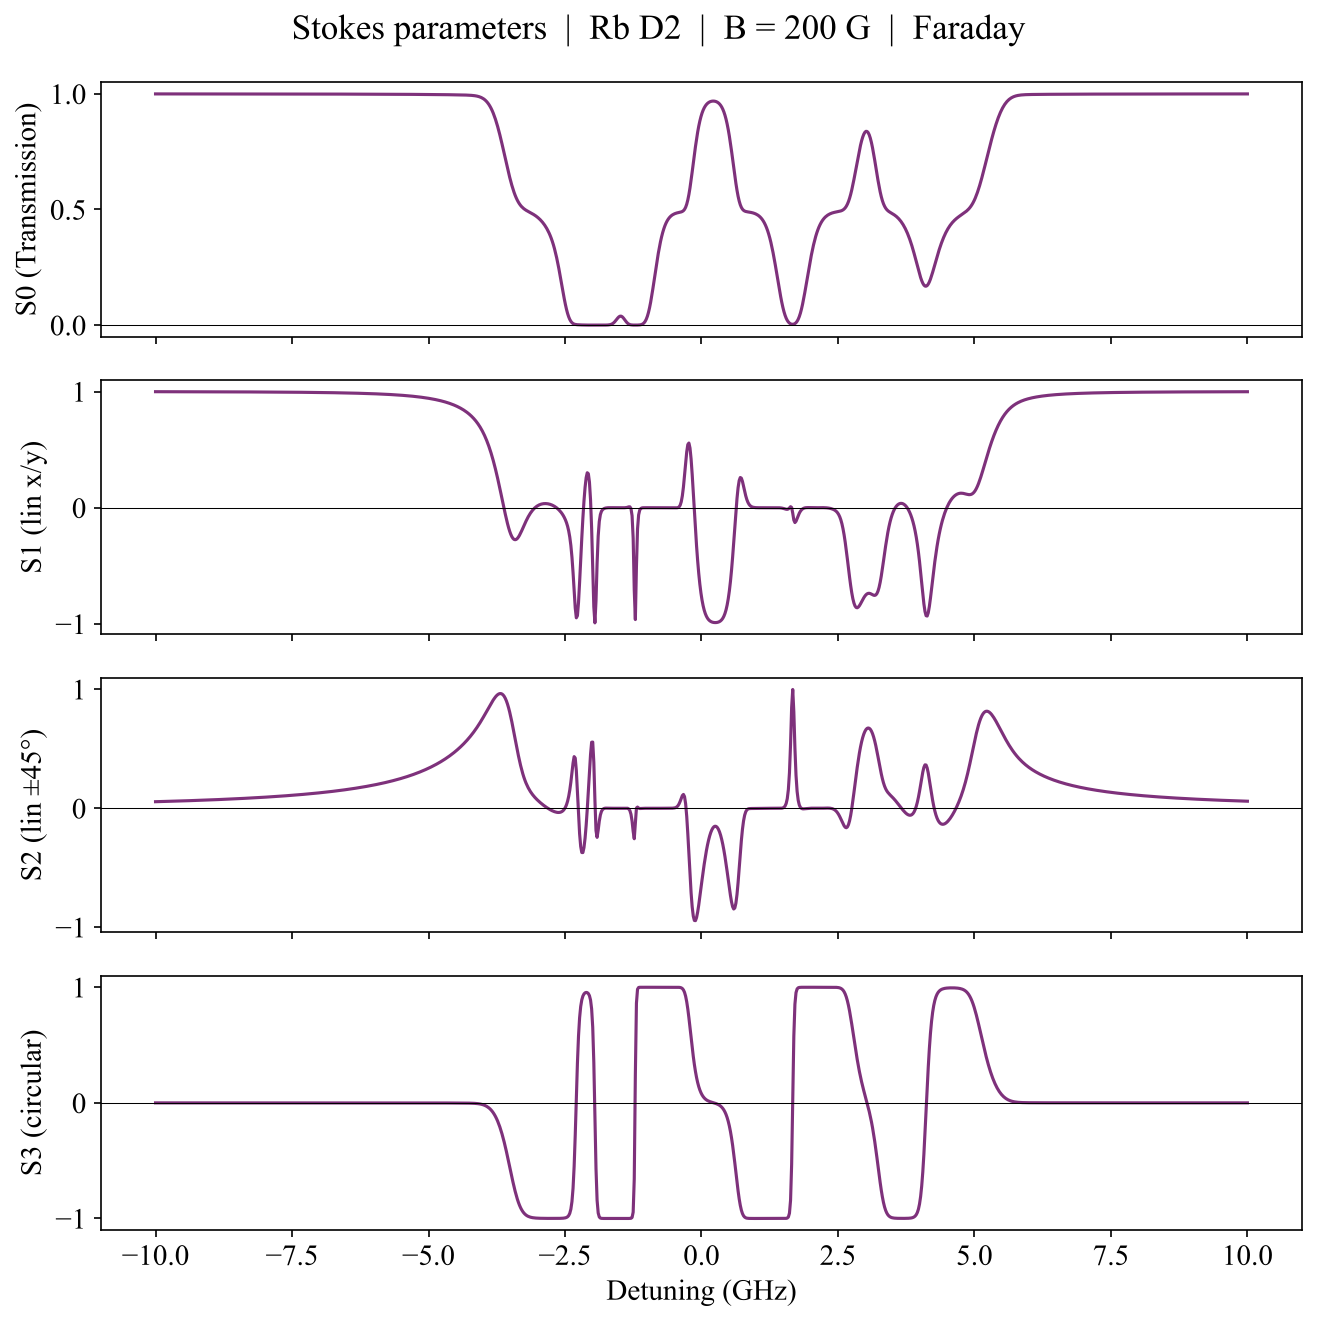

In [2]:
p = {'Elem':'Rb','Dline':'D2','T':60.,'lcell':75e-3,'Bfield':200}
S0, S1, S2, S3 = em.calculate(det, [1,0,0], p, outputs=['S0','S1','S2','S3'])

fig, axes = plt.subplots(4, 1, figsize=(9, 9), sharex=True)
for ax, y, label in zip(axes, [S0, S1, S2, S3],
                         ['S0 (Transmission)', 'S1 (lin x/y)', 'S2 (lin ±45°)', 'S3 (circular)']):
    ax.plot(det / 1e3, y)
    ax.set_ylabel(label)
    ax.axhline(0, color='k', lw=0.5)
axes[-1].set_xlabel('Detuning (GHz)')
fig.suptitle('Stokes parameters  |  Rb D2  |  B = 200 G  |  Faraday')
plt.tight_layout()


## Faraday rotation angle

The rotation angle of the polarisation plane is θ = ½ arctan(S2/S1).
It is proportional to S3 in the limit of small rotation.
Dispersive features arise near absorption resonances.

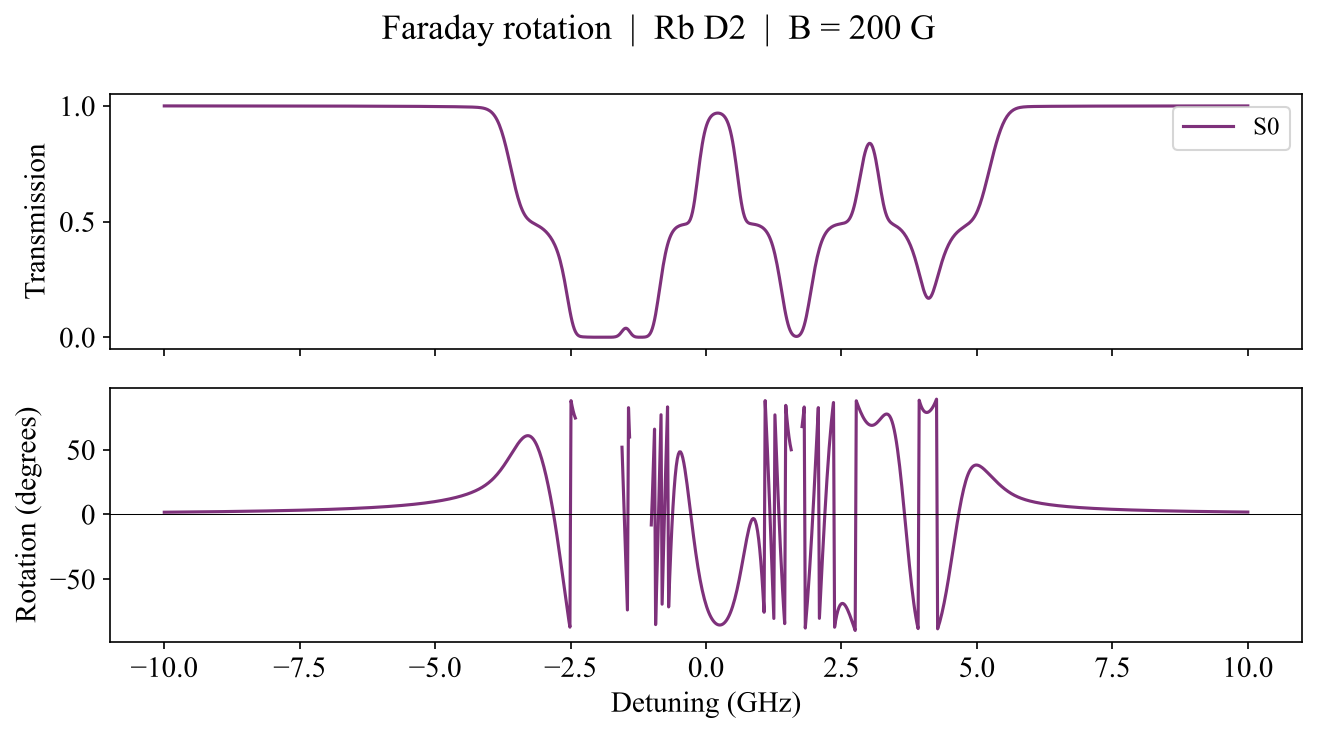

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
ax1.plot(det / 1e3, S0, label='S0')
ax1.set_ylabel('Transmission')
ax1.legend()

rotation_deg = 0.5 * np.degrees(np.arctan2(S2.real, S1.real))
# the rotation angle is only defined where light is transmitted;
# mask the opaque core, where S1, S2 -> 0/0 is numerical noise
rotation_deg = np.where(S0.real > 0.02, rotation_deg, np.nan)
ax2.plot(det / 1e3, rotation_deg)
ax2.set(xlabel='Detuning (GHz)', ylabel='Rotation (degrees)')
ax2.axhline(0, color='k', lw=0.5)
fig.suptitle('Faraday rotation  |  Rb D2  |  B = 200 G')
plt.tight_layout()


## Circular dichroism

Il and Ir are the left- and right-circularly polarised components of the
transmitted beam.  Their difference (circular dichroism) is directly related
to S3 and is sensitive to the sign of the magnetic field.

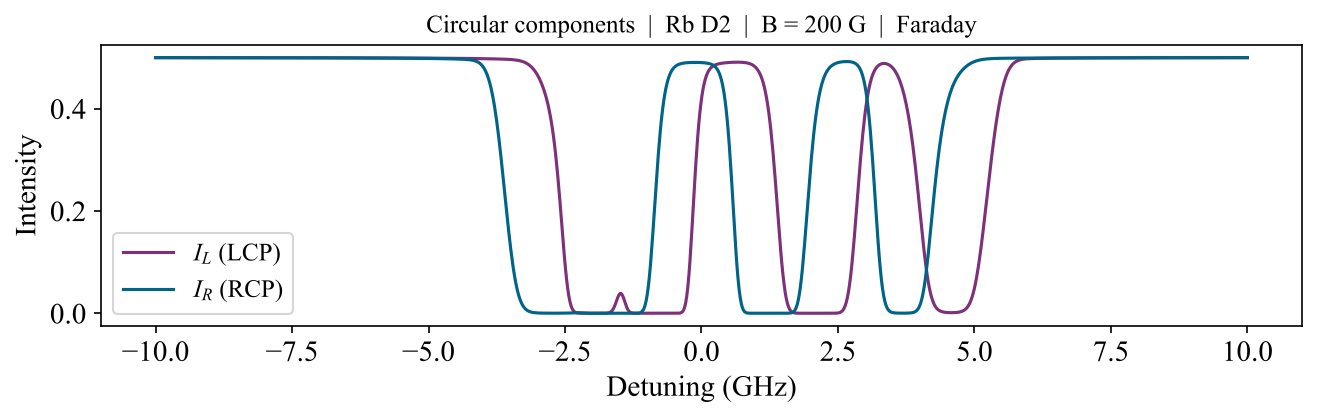

In [4]:
Il, Ir = em.calculate(det, [1,0,0], p, outputs=['Il','Ir'])

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(det / 1e3, Il, label=r'$I_L$ (LCP)')
ax.plot(det / 1e3, Ir, label=r'$I_R$ (RCP)')
ax.set(xlabel='Detuning (GHz)', ylabel='Intensity')
ax.legend()
ax.set_title('Circular components  |  Rb D2  |  B = 200 G  |  Faraday')
plt.tight_layout()


## Scanning the magnetic field

Peak S3 (degree of circular polarisation) vs field strength shows the
crossover from the weak-field (overlapping lines) to the strong-field
(isolated σ⁺/σ⁻ components) regime.

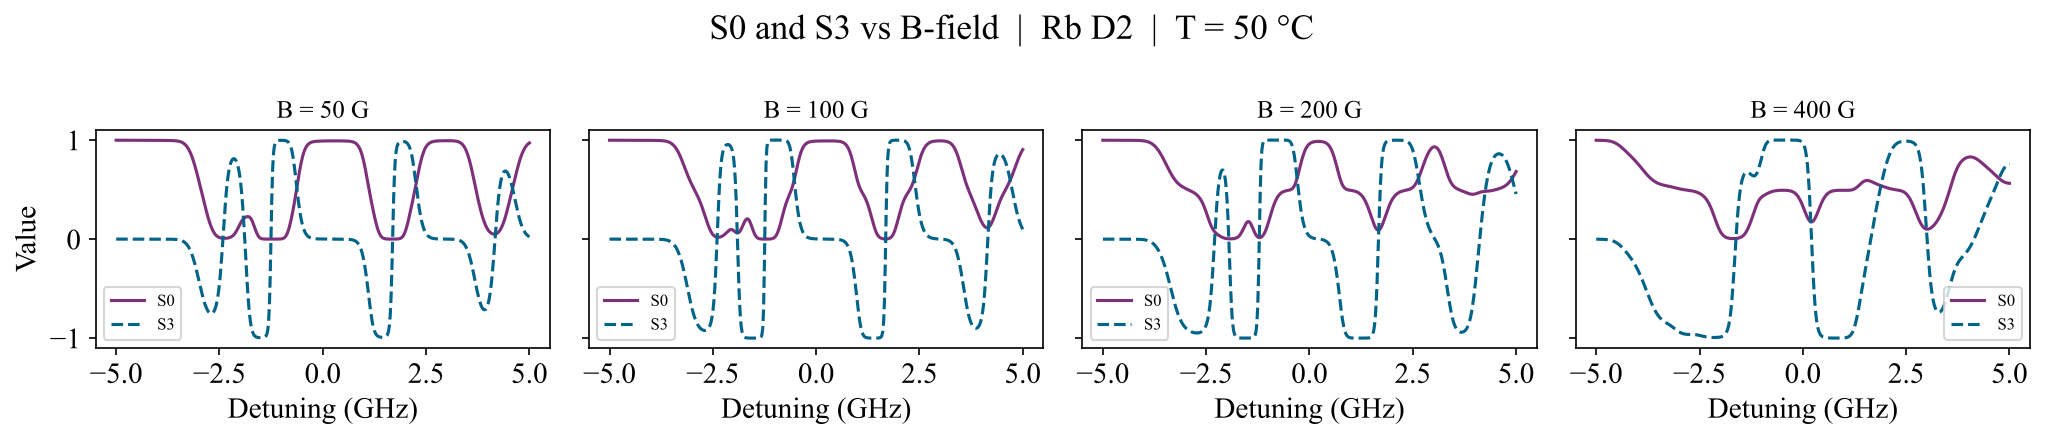

In [5]:
det_narrow = np.linspace(-5000, 5000, 500)
fields = [50, 100, 200, 400]
fig, axes = plt.subplots(1, len(fields), figsize=(14, 3), sharey=True)
for ax, B in zip(axes, fields):
    S0_B, S3_B = em.calculate(det_narrow, [1,0,0],
                               {'Elem':'Rb','Dline':'D2','T':50.,'lcell':75e-3,'Bfield':B},
                               outputs=['S0','S3'])
    ax.plot(det_narrow / 1e3, S0_B, label='S0')
    ax.plot(det_narrow / 1e3, S3_B, label='S3', ls='--')
    ax.set(xlabel='Detuning (GHz)', title=f'B = {B} G')
    ax.legend(fontsize=8)
axes[0].set_ylabel('Value')
fig.suptitle('S0 and S3 vs B-field  |  Rb D2  |  T = 50 °C')
plt.tight_layout()
